1. Ingesting NASA Li-ion Battery Telemetry (B0005)...
Data pipeline ready: 8,000 streaming instances loaded.

Rule-Based Controller class defined.

Running grid search across 27 hyperparameter configurations...

Grid search execution complete.
   Stability_Threshold  Margin_Delta  Cooldown_Window  Accuracy  \
0                  0.8          0.01               10  0.994125   
1                  0.8          0.01               50  0.993500   
2                  0.8          0.01              100  0.993000   
3                  0.8          0.05               10  0.992750   
4                  0.8          0.05               50  0.992750   
5                  0.8          0.05              100  0.992625   
6                  0.8          0.10               10  0.992750   
7                  0.8          0.10               50  0.992750   
8                  0.8          0.10              100  0.992750   
9                  0.9          0.01               10  0.994125   

   Total_Switches 

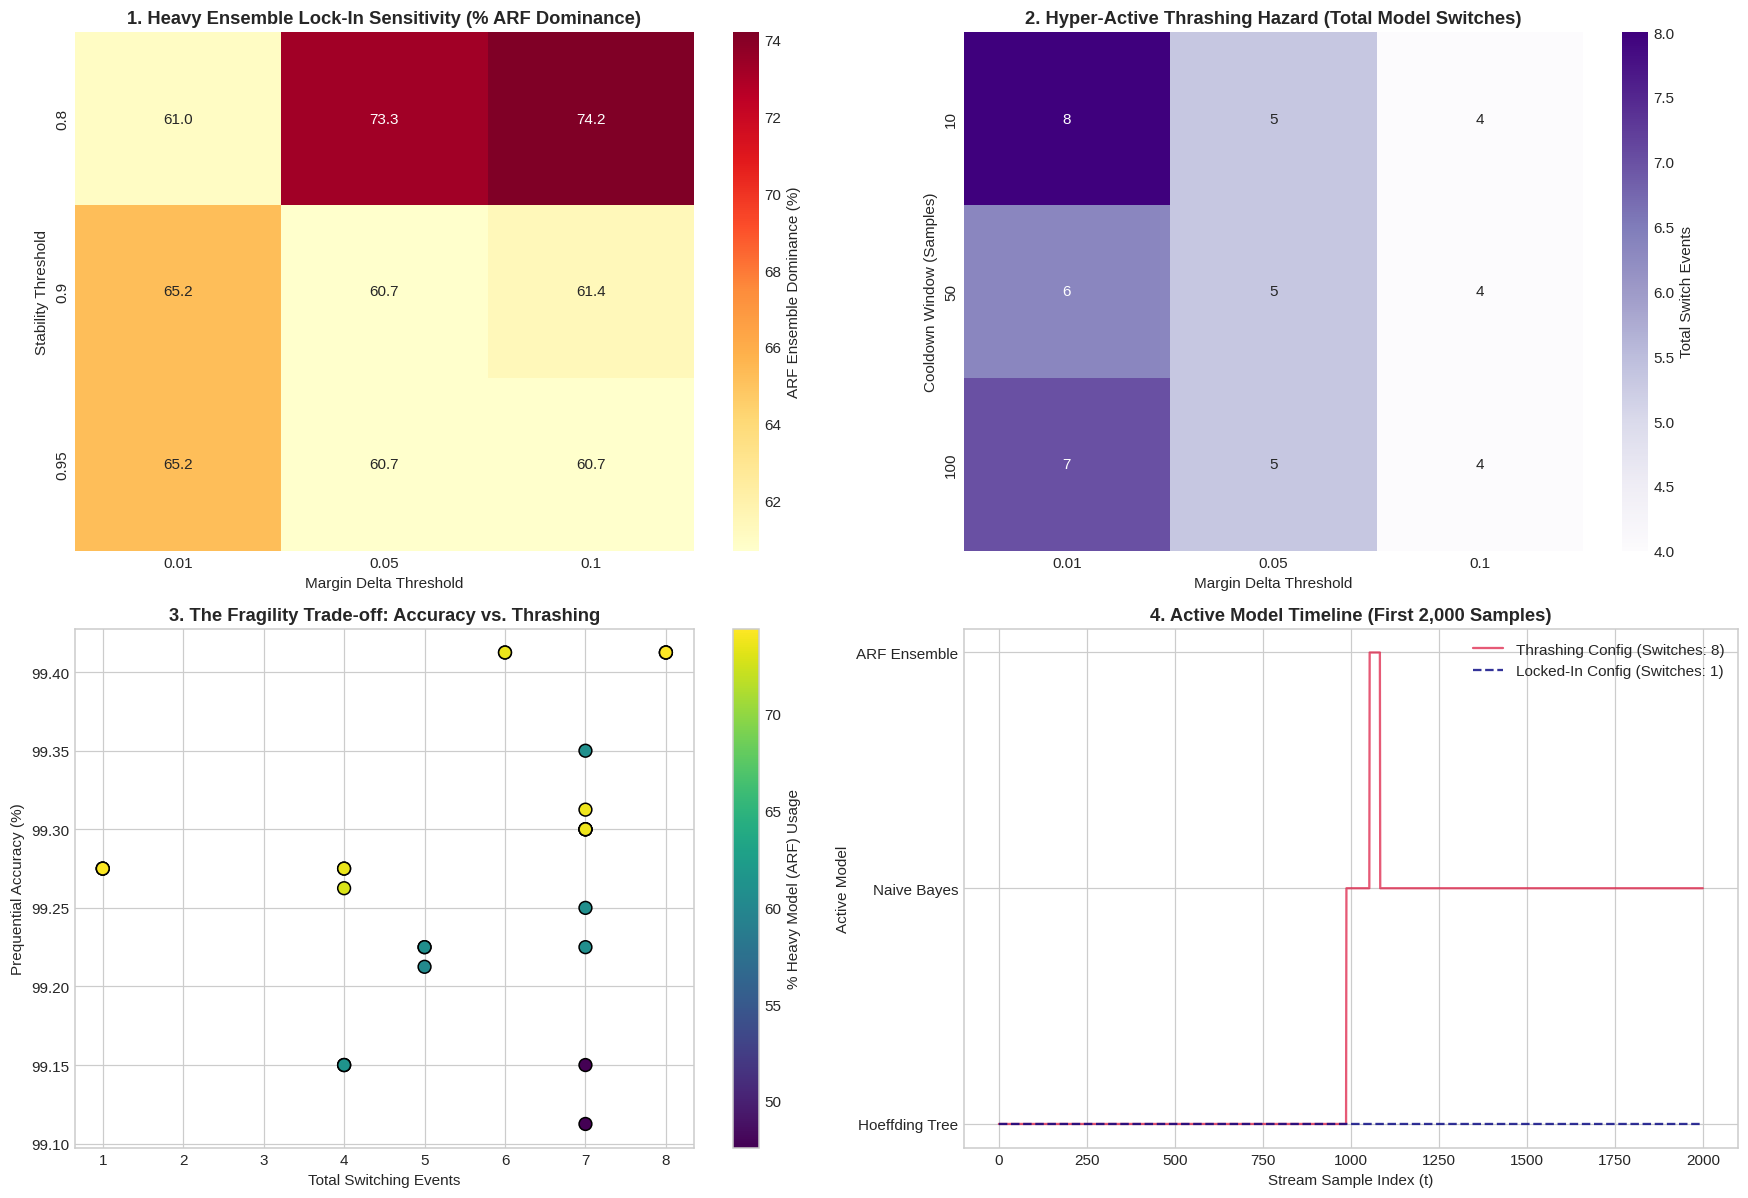

In [ ]:
# Install required libraries (uncomment if running in a new environment/Colab)
# !pip install river scipy pandas numpy matplotlib seaborn

import itertools
import os
import urllib.request
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
import seaborn as sns
from river import forest, metrics, naive_bayes, stream, tree

# Graphics configuration
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
plt.rcParams["figure.dpi"] = 110

# ---------------------------------------------------------
# 1. Ingesting NASA Li-ion Battery Telemetry (B0005)
# ---------------------------------------------------------
print("1. Ingesting NASA Li-ion Battery Telemetry (B0005)...")

DATA_URL = (
    "https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip"
)
ZIP_PATH = "NASA_Battery_Data.zip"
EXTRACT_DIR = "nasa_battery_extracted"

if not os.path.exists(ZIP_PATH):
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

for root, dirs, files in os.walk(EXTRACT_DIR):
    for f in files:
        if f.endswith(".zip"):
            try:
                with zipfile.ZipFile(os.path.join(root, f), "r") as inner_zip:
                    inner_zip.extractall(root)
            except Exception:
                pass

mat_file_path = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    if "B0005.mat" in files:
        mat_file_path = os.path.join(root, "B0005.mat")
        break

# Parse MATLAB arrays into continuous dataframe
mat_data = scipy.io.loadmat(mat_file_path)
cell_data = mat_data["B0005"][0, 0]["cycle"][0]

records = []
for cycle_idx, cycle_struct in enumerate(cell_data):
    op_type = str(cycle_struct["type"][0])
    data = cycle_struct["data"]
    if op_type in ["charge", "discharge"]:
        try:
            v = data["Voltage_measured"][0, 0].flatten()
            c = data["Current_measured"][0, 0].flatten()
            t = data["Temperature_measured"][0, 0].flatten()
            rel_t = data["Time"][0, 0].flatten()
            for i in range(len(v)):
                records.append(
                    {
                        "Cycle": cycle_idx,
                        "Voltage": float(v[i]),
                        "Current": float(c[i]),
                        "Temperature": float(t[i]),
                    }
                )
        except Exception:
            continue

df = pd.DataFrame(records)
df["Delta_Voltage"] = df["Voltage"].diff().fillna(0.0)
df["Delta_Temp"] = df["Temperature"].diff().fillna(0.0)
df["Power"] = df["Voltage"] * df["Current"]
df["Anomaly"] = ((df["Temperature"] >= 36.0) | (df["Voltage"] <= 2.7)).astype(
    int
)

# Use 8,000 streaming samples for fast grid evaluation
STREAM_SIZE = 8000
stream_df = df.iloc[:STREAM_SIZE].reset_index(drop=True)

print(f"Data pipeline ready: {len(stream_df):,} streaming instances loaded.\n")


# ---------------------------------------------------------
# 2. Rule-Based Threshold Controller Class
# ---------------------------------------------------------
class RuleBasedThresholdController:
    """Simulates traditional heuristic rule-based switching controllers.

    Switches active models based on hardcoded threshold conditions:
      1. Margin Delta: best_acc - current_acc > margin_delta
      2. Stability Threshold: rolling_acc < stability_threshold
      3. Cooldown Counter: steps_since_switch > cooldown_window
    """

    def __init__(
        self,
        stability_threshold=0.90,
        margin_delta=0.05,
        cooldown_window=50,
        window_size=100,
    ):
        self.stability_threshold = stability_threshold
        self.margin_delta = margin_delta
        self.cooldown_window = cooldown_window
        self.window_size = window_size

        # Instantiate candidate pool using updated River API
        self.models = {
            "HoeffdingTree": tree.HoeffdingTreeClassifier(),
            "NaiveBayes": naive_bayes.GaussianNB(),
            "ARF": forest.ARFClassifier(n_models=3, seed=42),
        }

        self.active_model = "HoeffdingTree"
        self.steps_since_switch = 0
        self.switch_count = 0

        # Sliding performance windows
        self.history = {m: [] for m in self.models}
        self.active_history = []
        self.model_selections = []

    def process_sample(self, x, y):
        # 1. Evaluate prediction with current active model
        active_pred = self.models[self.active_model].predict_one(x)
        if active_pred is None:
            active_pred = 0

        active_correct = 1.0 if active_pred == y else 0.0
        self.active_history.append(active_correct)
        self.model_selections.append(self.active_model)

        # 2. Evaluate candidate pool predictions (Shadow Mode)
        rolling_accs = {}
        for m_name, model in self.models.items():
            pred = model.predict_one(x)
            correct = 1.0 if pred == y else 0.0
            self.history[m_name].append(correct)

            # Compute rolling accuracy over window_size
            recent = self.history[m_name][-self.window_size :]
            rolling_accs[m_name] = sum(recent) / len(recent)

            # Update all candidate models
            model.learn_one(x, y)

        # 3. Apply Hardcoded Rule Checks
        self.steps_since_switch += 1
        current_acc = rolling_accs[self.active_model]
        best_candidate = max(rolling_accs, key=rolling_accs.get)
        best_acc = rolling_accs[best_candidate]

        # Rule evaluation
        rule_stability_tripped = current_acc < self.stability_threshold
        rule_margin_tripped = (best_acc - current_acc) > self.margin_delta
        rule_cooldown_passed = self.steps_since_switch >= self.cooldown_window

        if (
            (rule_stability_tripped or rule_margin_tripped)
            and rule_cooldown_passed
            and (best_candidate != self.active_model)
        ):
            self.active_model = best_candidate
            self.switch_count += 1
            self.steps_since_switch = 0


print("Rule-Based Controller class defined.\n")

# ---------------------------------------------------------
# 3. Hyperparameter Grid Search
# ---------------------------------------------------------
STABILITY_THRESHOLDS = [0.80, 0.90, 0.95]
MARGIN_DELTAS = [0.01, 0.05, 0.10]
COOLDOWN_WINDOWS = [10, 50, 100]

param_combinations = list(
    itertools.product(STABILITY_THRESHOLDS, MARGIN_DELTAS, COOLDOWN_WINDOWS)
)
print(
    f"Running grid search across {len(param_combinations)} hyperparameter configurations...\n"
)

grid_results = []
feature_cols = [
    "Voltage",
    "Current",
    "Temperature",
    "Delta_Voltage",
    "Delta_Temp",
    "Power",
]

for idx, (stab, margin, cooldown) in enumerate(param_combinations):
    controller = RuleBasedThresholdController(
        stability_threshold=stab,
        margin_delta=margin,
        cooldown_window=cooldown,
    )

    stream_iter = stream.iter_frame(
        X=stream_df[feature_cols], y=stream_df["Anomaly"]
    )
    for x, y in stream_iter:
        controller.process_sample(x, y)

    overall_acc = np.mean(controller.active_history)
    total_switches = controller.switch_count

    # Calculate model dominance ratios
    counts = pd.Series(controller.model_selections).value_counts(
        normalize=True
    )
    ht_ratio = counts.get("HoeffdingTree", 0.0) * 100
    nb_ratio = counts.get("NaiveBayes", 0.0) * 100
    arf_ratio = counts.get("ARF", 0.0) * 100

    dominant_model = counts.index[0]
    lockin_ratio = counts.iloc[0] * 100

    grid_results.append(
        {
            "Stability_Threshold": stab,
            "Margin_Delta": margin,
            "Cooldown_Window": cooldown,
            "Accuracy": overall_acc,
            "Total_Switches": total_switches,
            "HT_Ratio_%": ht_ratio,
            "NB_Ratio_%": nb_ratio,
            "ARF_Ratio_%": arf_ratio,
            "Dominant_Model": dominant_model,
            "LockIn_Ratio_%": lockin_ratio,
        }
    )

results_df = pd.DataFrame(grid_results)
print("Grid search execution complete.")
print(results_df.head(10))

# ---------------------------------------------------------
# 4. Visualization & Diagnostics
# ---------------------------------------------------------
fig = plt.figure(figsize=(16, 11))

# Plot 1: Model Dominance Lock-in Heatmap (Margin Delta vs Stability Threshold)
ax1 = fig.add_subplot(2, 2, 1)
pivot_lockin = results_df.pivot_table(
    index="Stability_Threshold",
    columns="Margin_Delta",
    values="ARF_Ratio_%",
    aggfunc="mean",
)
sns.heatmap(
    pivot_lockin,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    ax=ax1,
    cbar_kws={"label": "ARF Ensemble Dominance (%)"},
)
ax1.set_title(
    "1. Heavy Ensemble Lock-In Sensitivity (% ARF Dominance)",
    fontweight="bold",
)
ax1.set_xlabel("Margin Delta Threshold")
ax1.set_ylabel("Stability Threshold")

# Plot 2: Thrashing (Total Switches) Heatmap (Cooldown Window vs Margin Delta)
ax2 = fig.add_subplot(2, 2, 2)
pivot_switches = results_df.pivot_table(
    index="Cooldown_Window",
    columns="Margin_Delta",
    values="Total_Switches",
    aggfunc="mean",
)
sns.heatmap(
    pivot_switches,
    annot=True,
    fmt=".0f",
    cmap="Purples",
    ax=ax2,
    cbar_kws={"label": "Total Switch Events"},
)
ax2.set_title(
    "2. Hyper-Active Thrashing Hazard (Total Model Switches)",
    fontweight="bold",
)
ax2.set_xlabel("Margin Delta Threshold")
ax2.set_ylabel("Cooldown Window (Samples)")

# Plot 3: Accuracy vs. Switching Frequency Scatter Plot
ax3 = fig.add_subplot(2, 2, 3)
sc = ax3.scatter(
    results_df["Total_Switches"],
    results_df["Accuracy"] * 100,
    c=results_df["ARF_Ratio_%"],
    cmap="viridis",
    s=70,
    edgecolor="black",
)
cbar = plt.colorbar(sc, ax=ax3)
cbar.set_label("% Heavy Model (ARF) Usage")
ax3.set_title(
    "3. The Fragility Trade-off: Accuracy vs. Thrashing", fontweight="bold"
)
ax3.set_xlabel("Total Switching Events")
ax3.set_ylabel("Prequential Accuracy (%)")

# Plot 4: Timeline Trajectory - Fragile Thrashing vs. Rigid Lock-In
ax4 = fig.add_subplot(2, 2, 4)

# Run a hyper-thrashing configuration
ctrl_thrash = RuleBasedThresholdController(
    stability_threshold=0.95, margin_delta=0.01, cooldown_window=10
)
# Run a locked-in configuration
ctrl_locked = RuleBasedThresholdController(
    stability_threshold=0.80, margin_delta=0.10, cooldown_window=100
)

stream_iter = stream.iter_frame(
    X=stream_df[feature_cols], y=stream_df["Anomaly"]
)
for x, y in stream_iter:
    ctrl_thrash.process_sample(x, y)
    ctrl_locked.process_sample(x, y)

# Convert categorical models to integers for visualization
mapping = {"HoeffdingTree": 1, "NaiveBayes": 2, "ARF": 3}
thrash_timeline = [mapping[m] for m in ctrl_thrash.model_selections]
locked_timeline = [mapping[m] for m in ctrl_locked.model_selections]

ax4.plot(
    thrash_timeline[:2000],
    color="crimson",
    alpha=0.7,
    label=f"Thrashing Config (Switches: {ctrl_thrash.switch_count})",
)
ax4.plot(
    locked_timeline[:2000],
    color="navy",
    linestyle="--",
    alpha=0.8,
    label=f"Locked-In Config (Switches: {ctrl_locked.switch_count})",
)
ax4.set_yticks([1, 2, 3])
ax4.set_yticklabels(["Hoeffding Tree", "Naive Bayes", "ARF Ensemble"])
ax4.set_title(
    "4. Active Model Timeline (First 2,000 Samples)", fontweight="bold"
)
ax4.set_xlabel("Stream Sample Index (t)")
ax4.set_ylabel("Active Model")
ax4.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
!pip install river pandas matplotlib seaborn numpy -q

In [ ]:
from collections import deque
from itertools import product
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from river import ensemble, metrics, naive_bayes, tree
from river.datasets import synth
import seaborn as sns


# ==========================================
# 1. VERSION-AGNOSTIC MODEL LOADERS
# ==========================================
def get_arf_model():
    ARF = None
    try:
        from river import forest

        ARF = forest.ARFClassifier
    except (ImportError, AttributeError):
        try:
            ARF = ensemble.ARFClassifier
        except (ImportError, AttributeError):
            try:
                ARF = ensemble.AdaptiveRandomForestClassifier
            except (ImportError, AttributeError):
                pass

    if ARF is not None:
        for param in [
            {"n_models": 5, "seed": 42},
            {"n_trees": 5, "seed": 42},
            {"seed": 42},
        ]:
            try:
                return ARF(**param)
            except TypeError:
                continue

    return ensemble.BaggingClassifier(
        model=tree.HoeffdingTreeClassifier(), n_models=5, seed=42
    )


# Custom robust rolling Kappa calculation to prevent version API breaks
class CustomRollingKappa:

    def __init__(self, window_size=50):
        self.window_size = window_size
        self.history = deque(maxlen=window_size)

    def update(self, y_true, y_pred):
        self.history.append((y_true, y_pred))

    def get(self):
        if not self.history:
            return 0.0
        kappa_metric = metrics.CohenKappa()
        for yt, yp in self.history:
            kappa_metric.update(yt, yp)
        return kappa_metric.get() or 0.0


# ==========================================
# 2. OVERFLOW-SAFE CONCEPT DRIFT STREAM
# ==========================================
class SafeConceptDriftStream:
    """Wrapper around two streams that transitions safely without float exp overflow."""

    def __init__(self, stream, drift_stream, position=2000, width=1, seed=42):
        self.stream = stream
        self.drift_stream = drift_stream
        self.position = position
        self.width = max(width, 1)
        self.seed = seed

    @staticmethod
    def _safe_sigmoid(x):

        # Numerically stable sigmoid function preventing math.exp overflow

        if x >= 0:
            z = math.exp(-x)
            return 1.0 / (1.0 + z)
        else:
            z = math.exp(x)
            return z / (1.0 + z)

    def __iter__(self):
        rng = np.random.RandomState(self.seed)
        s1_iter = iter(self.stream)
        s2_iter = iter(self.drift_stream)
        sample_idx = 0

        while True:
            sample_idx += 1

            # Compute exponent safely without overflow
            v = 4.0 * float(sample_idx - self.position) / float(self.width)
            prob_drift = self._safe_sigmoid(v)

            x1, y1 = next(s1_iter)
            x2, y2 = next(s2_iter)

            if rng.random() < prob_drift:
                yield x2, y2
            else:
                yield x1, y1

    def take(self, n):
        for i, sample in enumerate(self):
            if i >= n:
                break
            yield sample


# ==========================================
# 3. DRIFT CONTROLLER CLASS
# ==========================================
class DynamicDriftController:

    def __init__(self, delta, cooldown, stability_threshold, window_size=50):
        self.delta = delta
        self.cooldown = cooldown
        self.stability_threshold = stability_threshold

        self.models = {
            "HT": tree.HoeffdingTreeClassifier(),
            "GNB": naive_bayes.GaussianNB(),
            "ARF": get_arf_model(),
        }

        self.rolling_kappas = {
            m: CustomRollingKappa(window_size=window_size) for m in self.models
        }
        self.overall_kappa = metrics.CohenKappa()

        self.active_model = "HT"
        self.cooldown_counter = 0
        self.switches = 0

    def process_sample(self, x, y):
        # Step 1: Prequential Evaluation
        preds = {}
        for name, model in self.models.items():
            preds[name] = model.predict_one(x)
            if preds[name] is not None:
                self.rolling_kappas[name].update(y, preds[name])

        active_pred = preds[self.active_model]
        if active_pred is not None:
            self.overall_kappa.update(y, active_pred)

        # Step 2: Online Model Training
        for model in self.models.values():
            model.learn_one(x, y)

        # Step 3: Controller Switching Logic
        if self.cooldown_counter > 0:
            self.cooldown_counter -= 1
        else:
            active_kappa = self.rolling_kappas[self.active_model].get()

            best_model = self.active_model
            best_kappa = active_kappa

            for name, metric in self.rolling_kappas.items():
                val = metric.get()
                if val > best_kappa:
                    best_kappa = val
                    best_model = name

            instability_triggered = active_kappa < self.stability_threshold
            margin_triggered = (best_kappa - active_kappa) > self.delta

            if (instability_triggered or margin_triggered) and (
                best_model != self.active_model
            ):
                self.active_model = best_model
                self.switches += 1
                self.cooldown_counter = self.cooldown

        return active_pred


# ==========================================
# 4. STREAM GENERATOR FACTORY
# ==========================================
def generate_drift_streams(n_samples=4000):
    s1 = synth.SEA(variant=0, seed=42)
    s2 = synth.SEA(variant=1, seed=42)

    return {
        "Abrupt": SafeConceptDriftStream(
            stream=s1, drift_stream=s2, position=2000, width=1
        ),
        "Gradual": SafeConceptDriftStream(
            stream=s1, drift_stream=s2, position=2000, width=800
        ),
        "Incremental": synth.Hyperplane(mag_change=0.001, seed=42),
    }


# ==========================================
# 5. GRID SEARCH BENCHMARK RUNNER
# ==========================================
def run_optimization_grid():
    n_samples = 4000
    param_grid = {
        "delta": [0.02, 0.05, 0.10],
        "cooldown": [20, 50, 100],
        "stability": [0.30, 0.50, 0.70],
    }

    grid_combinations = list(
        product(
            param_grid["delta"], param_grid["cooldown"], param_grid["stability"]
        )
    )
    results = []

    print(
        f"Running grid search across {len(grid_combinations)} configurations per drift type...\n"
    )

    for drift_name in ["Abrupt", "Gradual", "Incremental"]:
        print(f"Evaluating Drift Type: {drift_name}")

        for delta, cooldown, stability in grid_combinations:
            # Re-instantiate stream for each grid pass
            streams = generate_drift_streams(n_samples=n_samples)
            stream = streams[drift_name]

            controller = DynamicDriftController(
                delta=delta, cooldown=cooldown, stability_threshold=stability
            )

            # Process stream samples
            for x, y in stream.take(n_samples):
                controller.process_sample(x, y)

            results.append(
                {
                    "drift_type": drift_name,
                    "delta": delta,
                    "cooldown": cooldown,
                    "stability": stability,
                    "overall_kappa": controller.overall_kappa.get(),
                    "total_switches": controller.switches,
                }
            )

    return pd.DataFrame(results)


# ==========================================
# 6. ENTRY POINT EXECUTION
# ==========================================
if __name__ == "__main__":
    df_results = run_optimization_grid()
    print("\n--- Top Performers by Drift Type ---")
    top_results = df_results.sort_values(
        by=["drift_type", "overall_kappa"], ascending=[True, False]
    )
    print(top_results.groupby("drift_type").head(3))

Running grid search across 27 configurations per drift type...

Evaluating Drift Type: Abrupt
Evaluating Drift Type: Gradual
Evaluating Drift Type: Incremental

--- Top Performers by Drift Type ---
     drift_type  delta  cooldown  stability  overall_kappa  total_switches
21       Abrupt   0.10        50        0.3       0.914129               5
22       Abrupt   0.10        50        0.5       0.914129               5
23       Abrupt   0.10        50        0.7       0.914129               5
48      Gradual   0.10        50        0.3       0.900540               5
49      Gradual   0.10        50        0.5       0.900540               5
50      Gradual   0.10        50        0.7       0.900540               5
63  Incremental   0.05        20        0.3       0.821865               3
64  Incremental   0.05        20        0.5       0.821865               3
65  Incremental   0.05        20        0.7       0.821865               3
